# Lab 5: PCA of land-cover patches and auto-encoder super-resolution

**Data (Google Earth Engine):** Sentinel-2 L2A (`COPERNICUS/S2_SR_HARMONIZED`), cloud-masked median composite, summer 2023;
ESA WorldCover 10 m 2021 (`ESA/WorldCover/v200`) for the land-cover tags.
**Area:** Gdańsk – Gdynia – Sopot (Tricity), the Kashubian forests and the Gulf of Gdańsk — all three classes in one region.

## 0. Setup

In [1]:
import warnings, time
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from concurrent.futures import ThreadPoolExecutor
from pyproj import Transformer
import plotly.express as px

In [2]:
import tensorflow as tf
print('TensorFlow', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))   # [] = CPU only

TensorFlow 2.18.1
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
import ee
PROJECT = 'commanding-air-494108-v2'
ee.Authenticate()
ee.Initialize(project=PROJECT)

## Task 1: PCA of land-cover patches

### 1.1 Data: Sentinel-2 composite and land-cover tags

10 spectral bands are used (the 20 m bands are resampled to 10 m). Only scenes with less than 10 % cloud cover are used for the median composite.
WorldCover classes: 50 = built-up (*urban*), 10 = tree cover (*forest*), 80 = permanent water bodies (*water*).

In [9]:
AOI = ee.Geometry.Rectangle([17.9, 54.15, 19.2, 54.75])    # Tricity, Kashubia, Gulf of Gdansk
BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
PATCH = 200        # pixels
RES = 10           # m -> one patch = 2 km x 2 km

def mask_s2(img):
    scl = img.select('SCL')
    ok = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))   # shadow, clouds, cirrus
    return img.updateMask(ok)

s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
        .filterDate('2023-06-01', '2023-08-31')
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
        .map(mask_s2)
        .select(BANDS)
        .median())

worldcover = ee.Image('ESA/WorldCover/v200/2021').select('Map')
stack = s2.toUint16().addBands(worldcover.toUint16())
print(stack.bandNames().getInfo())

['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'Map']


### 1.2 Patch centres

Random points are drawn inside each of the three WorldCover classes; points closer than 2 km are removed so that the patches do not overlap.

In [10]:
CLASSES = {0: 'urban', 1: 'forest', 2: 'water'}
N_CANDIDATES = 1000      # per class, before filtering

cls_img = worldcover.remap([50, 10, 80], [0, 1, 2]).rename('cls')    # other classes are masked
pts = cls_img.stratifiedSample(numPoints=N_CANDIDATES, classBand='cls', region=AOI,
                               scale=100, seed=42, geometries=True, tileScale=4)
lonlat = np.array([f['geometry']['coordinates'] for f in pts.getInfo()['features']])
print('Candidate points:', len(lonlat))

to_utm = Transformer.from_crs('EPSG:4326', 'EPSG:32634', always_xy=True)
xs, ys = to_utm.transform(lonlat[:, 0], lonlat[:, 1])
centres = np.c_[xs, ys]

rng = np.random.default_rng(0)
keep = []
for i in rng.permutation(len(centres)):
    if all(np.max(np.abs(centres[i] - centres[j])) >= PATCH * RES for j in keep):
        keep.append(i)
centres = centres[keep]
print('Non-overlapping centres:', len(centres))

Candidate points: 3000
Non-overlapping centres: 522


### 1.3 Downloading the patches and assigning the tags

- **urban** if ≥ 30 % of the pixels are built-up,
- **forest** if ≥ 80 % are tree cover,
- **water** if ≥ 90 % are water,
- otherwise the patch is mixed and discarded.

The classes are then subsampled to the same number of patches.

In [11]:
def get_patch(cx, cy, crs='EPSG:32634', retries=3):
    req = {
        'expression': stack,
        'fileFormat': 'NUMPY_NDARRAY',
        'grid': {
            'dimensions': {'width': PATCH, 'height': PATCH},
            'affineTransform': {'scaleX': RES, 'shearX': 0, 'translateX': cx - PATCH * RES / 2,
                                'shearY': 0, 'scaleY': -RES, 'translateY': cy + PATCH * RES / 2},
            'crsCode': crs,
        },
    }
    for k in range(retries):
        try:
            arr = ee.data.computePixels(req)
            spec = np.stack([arr[b] for b in BANDS], axis=-1)       # (200, 200, 10)
            lc = arr['Map']
            return spec, np.mean(lc == 50), np.mean(lc == 10), np.mean(lc == 80)
        except Exception:
            time.sleep(2 * (k + 1))
    return None

t0 = time.time()
downloaded = []
with ThreadPoolExecutor(max_workers=8) as ex:
    for k, r in enumerate(ex.map(lambda c: get_patch(*c), centres), 1):
        downloaded.append(r)
        if k % 50 == 0 or k == len(centres):
            print(f'{k}/{len(centres)} patches downloaded ({time.time() - t0:.0f} s)', flush=True)
print(f'Downloaded in {time.time() - t0:.0f} s')

patches, labels = [], []
for r in downloaded:
    if r is None:
        continue
    spec, built, tree, water = r
    if np.any(spec.sum(-1) == 0):          # no data / masked pixels
        continue
    if built >= 0.3:
        patches.append(spec); labels.append(0)
    elif tree >= 0.8:
        patches.append(spec); labels.append(1)
    elif water >= 0.9:
        patches.append(spec); labels.append(2)
patches, labels = np.array(patches, dtype=np.uint16), np.array(labels)
print('All:', {CLASSES[k]: int((labels == k).sum()) for k in CLASSES})

# balance the classes
n_min = min(int((labels == k).sum()) for k in CLASSES)
keep = np.sort(np.concatenate([rng.choice(np.where(labels == k)[0], n_min, replace=False) for k in CLASSES]))
patches, labels = patches[keep], labels[keep]
print('Balanced:', patches.shape, {CLASSES[k]: int((labels == k).sum()) for k in CLASSES})

np.savez_compressed('lab5_patches.npz', patches=patches, labels=labels)

50/522 patches downloaded (12 s)
100/522 patches downloaded (24 s)
150/522 patches downloaded (36 s)
200/522 patches downloaded (46 s)
250/522 patches downloaded (58 s)
300/522 patches downloaded (68 s)
350/522 patches downloaded (79 s)
400/522 patches downloaded (90 s)
450/522 patches downloaded (102 s)
500/522 patches downloaded (113 s)
522/522 patches downloaded (118 s)
Downloaded in 118 s
All: {'urban': 20, 'forest': 38, 'water': 163}
Balanced: (60, 200, 200, 10) {'urban': 20, 'forest': 20, 'water': 20}


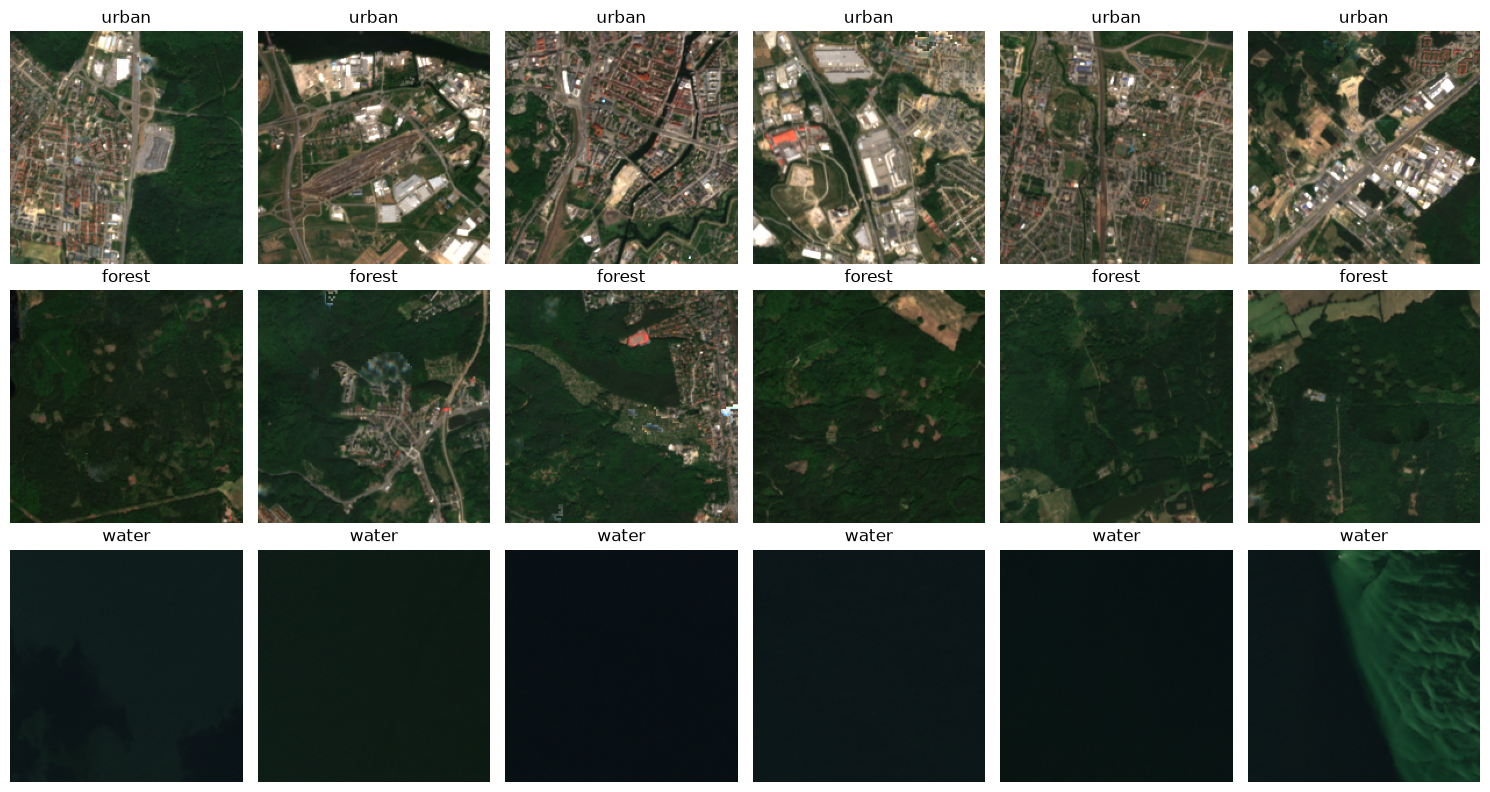

In [12]:
def rgb(p):
    img = p[..., [2, 1, 0]].astype(float) / 10000 * 3.5      # B4, B3, B2, brightened
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for row, k in enumerate(CLASSES):
    for ax, i in zip(axes[row], np.where(labels == k)[0][:6]):
        ax.imshow(rgb(patches[i])); ax.set_title(CLASSES[k]); ax.axis('off')
plt.tight_layout(); plt.show()

### 1.4 PCA on the patch pixels

Each patch is averaged in 10×10 blocks (20×20 pixels × 10 bands = 4000 values) and flattened.
Every value is standardised (zero mean, unit variance), then PCA reduces the 4000 dimensions to 3.

In [13]:
def features_pixels(P, block=10):
    R = P.astype(np.float32) / 10000.0
    n, h, w, c = R.shape
    R = R.reshape(n, h // block, block, w // block, block, c).mean(axis=(2, 4))
    return R.reshape(n, -1)

X_pix = StandardScaler().fit_transform(features_pixels(patches))
pca_pix = PCA(n_components=3)
Z_pix = pca_pix.fit_transform(X_pix)
print('Input dimension:', X_pix.shape[1])
print('Explained variance of PC1-PC3:', pca_pix.explained_variance_ratio_.round(3),
      '| total:', pca_pix.explained_variance_ratio_.sum().round(3))

Input dimension: 4000
Explained variance of PC1-PC3: [0.656 0.137 0.026] | total: 0.819


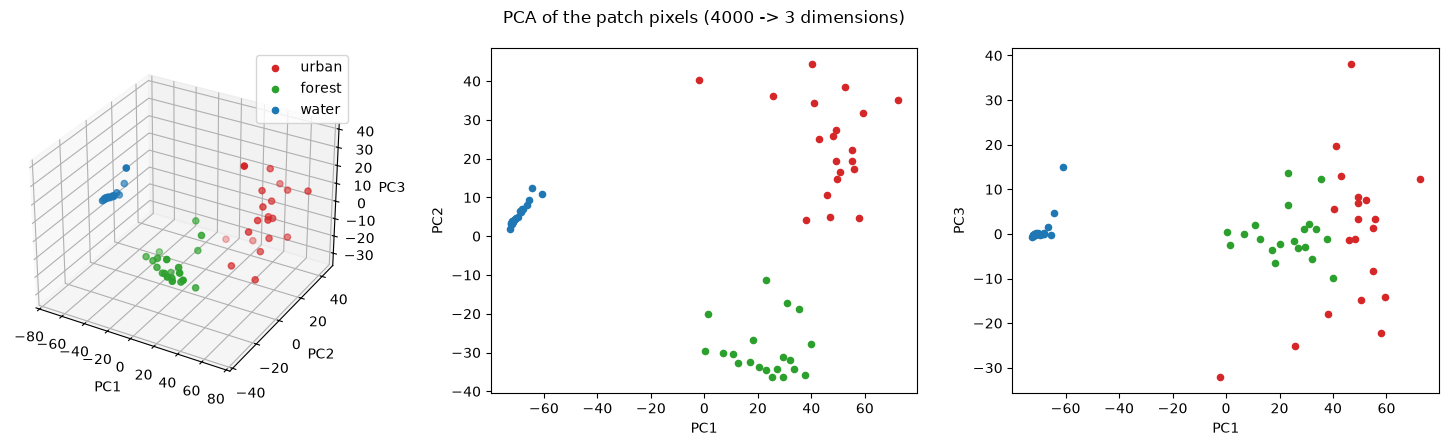

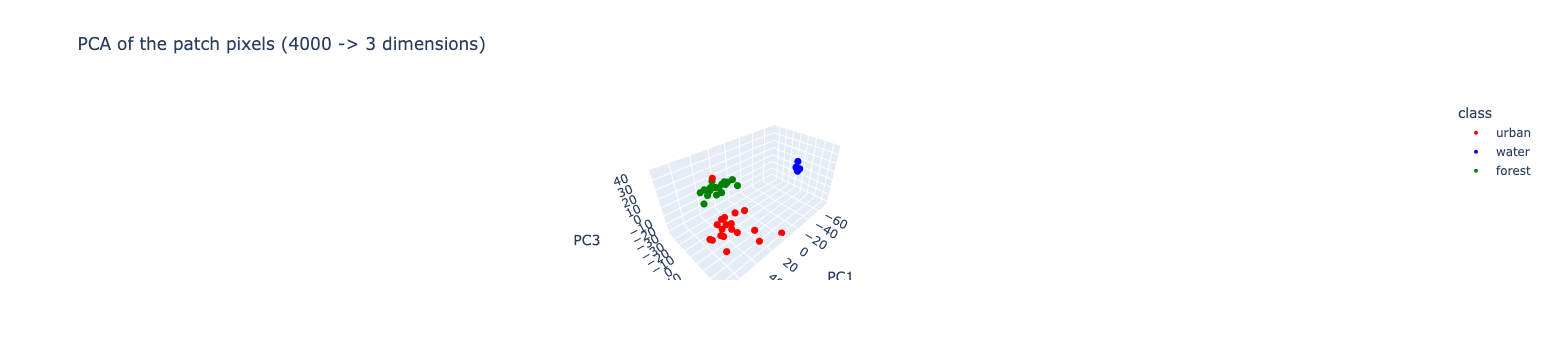

In [14]:
COLORS = {0: 'tab:red', 1: 'tab:green', 2: 'tab:blue'}

def plot_pcs(Z, title):
    fig = plt.figure(figsize=(15, 4.5))
    ax = fig.add_subplot(1, 3, 1, projection='3d')
    for k in CLASSES:
        ax.scatter(*Z[labels == k].T, c=COLORS[k], label=CLASSES[k], s=20)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3'); ax.legend()
    for j, (a, b) in enumerate([(0, 1), (0, 2)]):
        ax = fig.add_subplot(1, 3, j + 2)
        for k in CLASSES:
            ax.scatter(Z[labels == k, a], Z[labels == k, b], c=COLORS[k], label=CLASSES[k], s=20)
        ax.set_xlabel(f'PC{a + 1}'); ax.set_ylabel(f'PC{b + 1}')
    fig.suptitle(title); plt.tight_layout(); plt.show()

    # interactive 3-D plot (rotate with the mouse)
    df = pd.DataFrame(Z, columns=['PC1', 'PC2', 'PC3']); df['class'] = [CLASSES[k] for k in labels]
    px.scatter_3d(df, x='PC1', y='PC2', z='PC3', color='class',
                  color_discrete_map={'urban': 'red', 'forest': 'green', 'water': 'blue'},
                  title=title).update_traces(marker_size=4).show()

plot_pcs(Z_pix, 'PCA of the patch pixels (4000 -> 3 dimensions)')

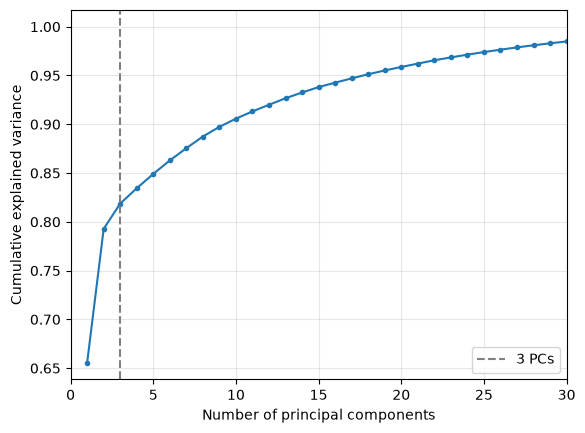

Components needed for 90 % of the variance: 10


In [16]:
pca_all = PCA().fit(X_pix)
cum = np.cumsum(pca_all.explained_variance_ratio_)
plt.plot(np.arange(1, len(cum) + 1), cum, marker='.')
plt.axvline(3, color='grey', ls='--', label='3 PCs')
plt.xlabel('Number of principal components'); plt.ylabel('Cumulative explained variance')
plt.xlim(0, 30); plt.legend(); plt.grid(alpha=0.3); plt.show()
print('Components needed for 90 % of the variance:', int(np.searchsorted(cum, 0.9) + 1))

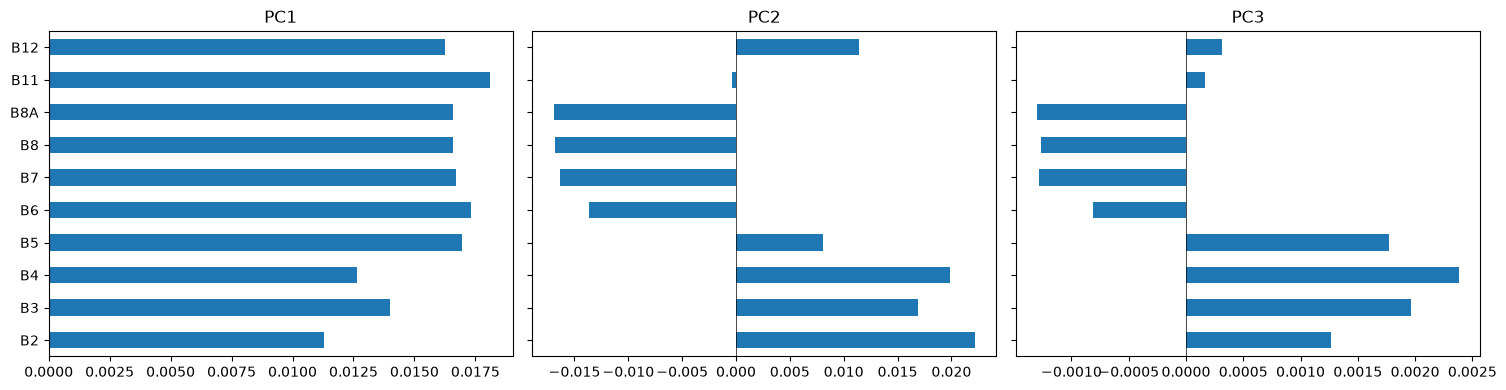

In [20]:
load = pca_pix.components_.reshape(3, 20, 20, len(BANDS))    
band_load = pd.DataFrame(load.mean(axis=(1, 2)).T, index=BANDS, columns=['PC1', 'PC2', 'PC3'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, pc in zip(axes, band_load.columns):
    band_load[pc].plot.barh(ax=ax, title=pc); ax.axvline(0, color='k', lw=0.5)
plt.tight_layout(); plt.show()

### 1.5 Clustering metrics

In [21]:
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z_pix)
print('Silhouette score (true tags):', round(silhouette_score(Z_pix, labels), 3))
print('ARI k-means vs tags:', round(adjusted_rand_score(labels, km.labels_), 3))

# Which land-cover classes ended up in which k-means cluster?
pd.crosstab(pd.Series([CLASSES[k] for k in labels], name='true class'),
            pd.Series(km.labels_, name='k-means cluster'))

Silhouette score (true tags): 0.712
ARI k-means vs tags: 1.0


k-means cluster,0,1,2
true class,,,
forest,0,20,0
urban,0,0,20
water,20,0,0


### 1.6 Findings

**Data.** 522 non-overlapping 2 × 2 km patches were downloaded from the Tricity / Kashubia / Gulf of Gdańsk area; 221 of them were pure enough to be tagged (20 urban, 38 forest, 163 water). After balancing, **60 patches (20 per class)** were used. The number of urban patches is the limiting factor: the Tricity urban area is small and a 2 × 2 km patch always contains streets, parks and water, so the built-up threshold had to be lowered to 30%.

1. **Clusters.** The three land-cover types form clearly separated clusters in PC space. Water is a very compact group far from the land patches along PC1. Urban and forest are separated along PC2. Urban and forest are the closest pair, they overlap in the PC1–PC3 view, and a few forest patches that contain settlements lie closer to the urban cluster. Urban patches are the most spread out, because built-up areas are heterogeneous, whereas the sea is almost uniform.
2. **Explained variance.** PC1, PC2 and PC3 explain 65.6%, 13.7% and 2.6% of the variance — 81.9% in total with 3 out of 4000 dimensions. Ten components are needed for 90%. The remaining variance is mostly spatial detail, which is not needed to tell the classes apart.
3. **Clustering metrics.** The silhouette score in the 3-D PC space is 0.71 (> 0.5 = well-separated clusters). k-means with k = 3, run without the tags, reproduced the land-cover classes exactly: adjusted Rand index = 1.0, every class was assigned to its own cluster (20/20/20).
4. **Meaning of the PCs.** PC1 has positive loadings of similar size in all bands, so it represents overall brightness. PC2 has positive loadings in the visible bands (B2–B5) and B12 and negative loadings in the red-edge/NIR bands (B6–B8A), so it is a vegetation contrast. The band-averaged loadings of PC3 are about ten times smaller, so PC3 mainly describes the spatial arrangement inside the patch rather than its spectrum, which explains why it does not separate the classes well.
5. **Limitations.** PCA is linear and unsupervised, it keeps the directions of largest variance, which here happen to coincide with the class differences because the three classes are spectrally very different. For classes with more similar spectra (e.g. forest vs. grassland) or nonlinear structure, PCA could fail and nonlinear methods would be needed. The dataset is small, the tags come from WorldCover thresholds (some patches are mixed), and the composite may still contain small cloud remnants.

## Task 2: Auto-encoder super-resolution

> **Note:** the auto-encoder code shared in class was not available, so a standard convolutional auto-encoder in Keras is used.

### 2.1 Idea

Super-resolution (SR) estimates a high-resolution (HR) image from a low-resolution (LR) one.
There is no Sentinel-2 image with a better resolution than 10 m to learn from, so the training pairs are made from the image itself:

1. **HR** = the original 10 m Sentinel-2 image (the target),
2. **LR** = the same image degraded to 20 m (2×2 pixel averaging, i.e. a larger sensor pixel),
3. **input** = LR upsampled back to the 10 m grid with bicubic interpolation (blurred).

The auto-encoder learns the function $f:\ \text{blurred 10 m} \rightarrow \text{sharp 10 m}$.
The encoder compresses the patch into a code (feature maps at half resolution), and the decoder reconstructs the sharp patch from the code.
The result is compared with plain bicubic interpolation, which is the baseline every SR method has to beat.

Image: a 10 × 10 km Sentinel-2 scene of Gdańsk (city, port, sea and forest), bands B4, B3, B2, B8 (all native 10 m).

In [22]:
import tensorflow as tf

SR_BANDS = ['B4', 'B3', 'B2', 'B8']          # red, green, blue, NIR (all 10 m)
SIZE = 1024                                   # pixels -> 10.24 km x 10.24 km
cx, cy = to_utm.transform(18.60, 54.37)       # Gdansk

req = {
    'expression': s2.select(SR_BANDS).toUint16(),
    'fileFormat': 'NUMPY_NDARRAY',
    'grid': {
        'dimensions': {'width': SIZE, 'height': SIZE},
        'affineTransform': {'scaleX': RES, 'shearX': 0, 'translateX': cx - SIZE * RES / 2,
                            'shearY': 0, 'scaleY': -RES, 'translateY': cy + SIZE * RES / 2},
        'crsCode': 'EPSG:32634',
    },
}
arr = ee.data.computePixels(req)
hr = np.stack([arr[b] for b in SR_BANDS], axis=-1).astype(np.float32) / 10000.0   # reflectance
print('HR image:', hr.shape, '| reflectance range:', hr.min().round(3), '-', hr.max().round(3))
np.save('lab5_gdansk_hr.npy', hr)

HR image: (1024, 1024, 4) | reflectance range: 0.004 - 1.129


### 2.2 Degrading the image: HR → LR → bicubic

HR (1024, 1024, 4) | LR (512, 512, 4) | bicubic (1024, 1024, 4)


2026-11-19 12:13:00.118841: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5 Pro
2026-11-19 12:13:00.118897: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-11-19 12:13:00.118908: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1795086780.118966 2100207 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1795086780.119025 2100207 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


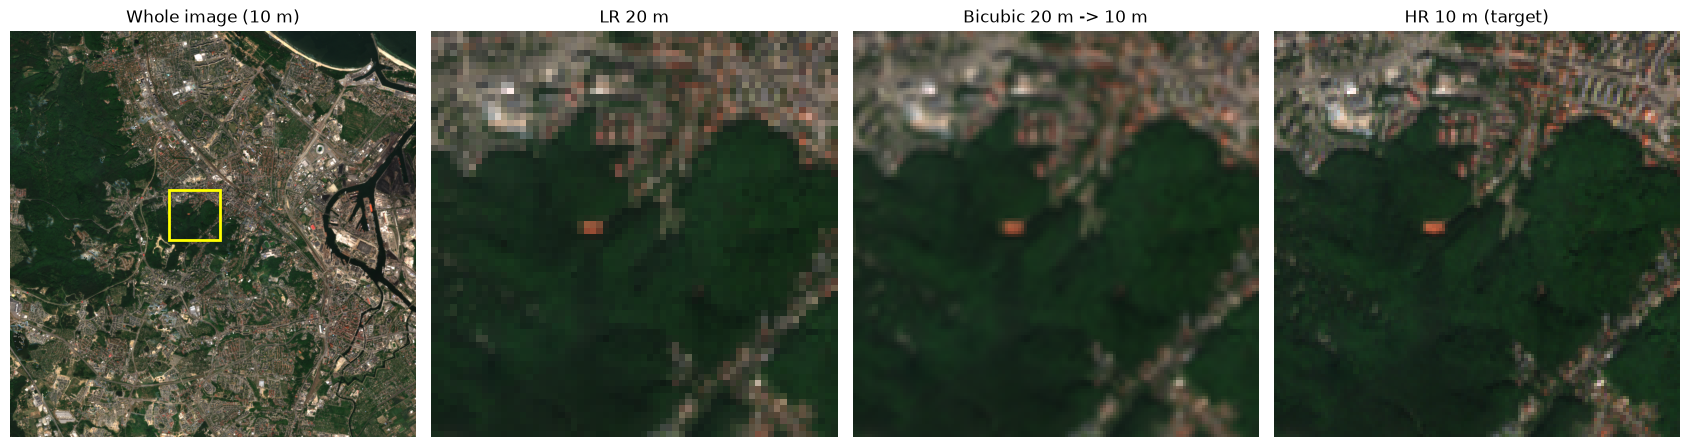

In [23]:
SCALE = 2

def downsample(x, s=SCALE):
    # average s x s blocks = image taken with an s-times larger pixel
    h, w, c = x.shape
    return x.reshape(h // s, s, w // s, s, c).mean(axis=(1, 3))

def upsample(x, s=SCALE):
    # bicubic interpolation back to the fine grid
    return tf.image.resize(x[None], (x.shape[0] * s, x.shape[1] * s), method='bicubic').numpy()[0]

def show_rgb(x):
    return np.clip(x[..., :3] * 3.5, 0, 1)    # bands are already in R, G, B order

lr = downsample(hr)               # 20 m, 512 x 512
lr_up = upsample(lr)              # 20 m information on the 10 m grid, 1024 x 1024
print('HR', hr.shape, '| LR', lr.shape, '| bicubic', lr_up.shape)

crop = np.s_[400:528, 400:528]    # 1.28 km x 1.28 km detail
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
axes[0].imshow(show_rgb(hr)); axes[0].set_title('Whole image (10 m)')
axes[0].add_patch(plt.Rectangle((400, 400), 128, 128, fill=False, color='yellow', lw=2))
axes[1].imshow(show_rgb(np.repeat(np.repeat(lr, 2, 0), 2, 1)[crop]), interpolation='nearest'); axes[1].set_title('LR 20 m')
axes[2].imshow(show_rgb(lr_up[crop])); axes[2].set_title('Bicubic 20 m -> 10 m')
axes[3].imshow(show_rgb(hr[crop])); axes[3].set_title('HR 10 m (target)')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

### 2.3 Training and test patches

The image is split spatially: the left 70% is used for training, the right 30% for testing,
so the test patches were never seen during training. Each sample is a 64×64-pixel pair.

In [24]:
P_SIZE = 64
split = int(0.7 * SIZE)

def crops(a, x0, x1, size=P_SIZE, stride=32):
    out = []
    for i in range(0, a.shape[0] - size + 1, stride):
        for j in range(x0, x1 - size + 1, stride):
            out.append(a[i:i + size, j:j + size])
    return np.array(out, dtype=np.float32)

X_train, Y_train = crops(lr_up, 0, split), crops(hr, 0, split)
X_test,  Y_test  = crops(lr_up, split, SIZE, stride=P_SIZE), crops(hr, split, SIZE, stride=P_SIZE)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (651, 64, 64, 4) | Test: (64, 64, 64, 4)


### 2.4 The auto-encoder

| Part | Layers | Output size (64×64 input) |
|---|---|---|
| Encoder | 2 × Conv 3×3 (32 filters, ReLU) → MaxPooling 2×2 → Conv 3×3 (64, ReLU) | 32×32×64 (the **code**) |
| Decoder | UpSampling 2×2 → Conv 3×3 (32, ReLU) → Conv 3×3 (4, linear) | 64×64×4 |

Two versions are compared:
- **plain auto-encoder** — the decoder has to rebuild the whole image from the code;
- **residual auto-encoder** — the bicubic input is added to the output, so the network only learns the missing details (HR − bicubic).

Convolutional layers are used instead of Dense layers: a Dense layer on a 64×64×4 patch would have 16 384 inputs per neuron,
while a convolution shares the same small 3×3 filter over the whole image and works for any image size.

In [25]:
from tensorflow.keras import layers

def autoencoder(residual=False, filters=32):
    inp = tf.keras.Input(shape=(None, None, len(SR_BANDS)))
    # encoder
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(inp)
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    x = layers.MaxPooling2D(2)(x)
    code_ = layers.Conv2D(2 * filters, 3, padding='same', activation='relu')(x)
    # decoder
    x = layers.UpSampling2D(2)(code_)
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    out = layers.Conv2D(len(SR_BANDS), 3, padding='same')(x)
    if residual:
        out = layers.Add()([inp, out])
    return tf.keras.Model(inp, out)

autoencoder(residual=True).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 4)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, None,      │      1,184 │ input_layer[0][0] │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, None,      │      9,248 │ conv2d[0][0]      │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, None,      │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, None,      │     18,496 │ max_pooling2d[0]… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, None,      │          0 │ conv2d_2[0][0]    │
│ (UpSampling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, None,      │     18,464 │ up_sampling2d[0]… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, None,      │      1,156 │ conv2d_3[0][0]    │
│                     │ None, 4)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, None,      │          0 │ input_layer[0][0… │
│                     │ None, 4)          │            │ conv2d_4[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 48,548 (189.64 KB)

 Trainable params: 48,548 (189.64 KB)

 Non-trainable params: 0 (0.00 B)

### 2.5 Training

Three experiments:
- **A** — plain auto-encoder, 20 epochs;
- **B** — residual auto-encoder, 20 epochs;
- **C** — residual auto-encoder + data augmentation (flips and 90° rotations → 8× more training patches), 20 epochs.

2026-11-19 12:20:44.588360: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


A plain AE                trained in 92 s, final val loss 2.45e-04
B residual AE             trained in 90 s, final val loss 2.05e-04
C residual AE + augment   trained in 719 s, final val loss 1.60e-04


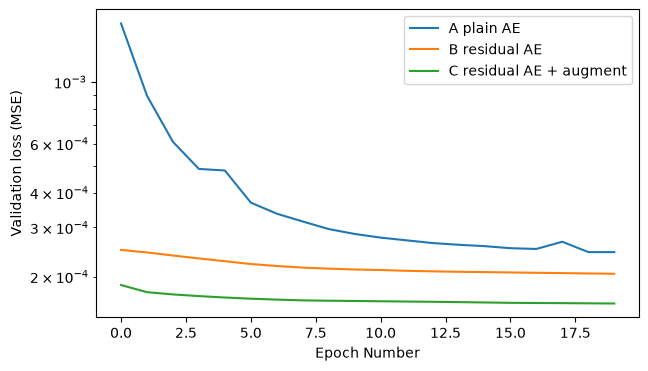

In [26]:
def augment(X, Y):
    Xs, Ys = [], []
    for k in range(4):
        for flip in (False, True):
            xa, ya = np.rot90(X, k, axes=(1, 2)), np.rot90(Y, k, axes=(1, 2))
            if flip:
                xa, ya = xa[:, :, ::-1], ya[:, :, ::-1]
            Xs.append(xa); Ys.append(ya)
    return np.concatenate(Xs), np.concatenate(Ys)

X_aug, Y_aug = augment(X_train, Y_train)

sr_experiments = {
    'A plain AE':              dict(residual=False, X=X_train, Y=Y_train, epochs=20),
    'B residual AE':           dict(residual=True,  X=X_train, Y=Y_train, epochs=20),
    'C residual AE + augment': dict(residual=True,  X=X_aug,   Y=Y_aug,   epochs=20),
}

sr_models, sr_hist = {}, {}
for name, e in sr_experiments.items():
    tf.keras.utils.set_random_seed(0)
    m = autoencoder(residual=e['residual'])
    m.compile(loss='mean_squared_error', optimizer=tf.keras.optimizers.Adam(0.001))
    t0 = time.time()
    h = m.fit(e['X'], e['Y'], epochs=e['epochs'], batch_size=16, validation_split=0.1, verbose=False)
    sr_models[name], sr_hist[name] = m, h.history
    print(f"{name:25s} trained in {time.time() - t0:.0f} s, final val loss {h.history['val_loss'][-1]:.2e}")

plt.figure(figsize=(7, 4))
for name, h in sr_hist.items():
    plt.plot(h['val_loss'], label=name)
plt.yscale('log'); plt.xlabel('Epoch Number'); plt.ylabel('Validation loss (MSE)'); plt.legend(); plt.show()

### 2.6 Does it enhance the resolution? (test area)

Quality measures, computed against the true 10 m image on the test patches:
- **PSNR** (peak signal-to-noise ratio, dB) — higher is better; +1 dB is a noticeable improvement;
- **SSIM** (structural similarity, 0–1) — how well edges and textures are preserved; 1 = identical.

In [27]:
MAX_VAL = float(Y_test.max())

def scores(pred, target=Y_test):
    p, t = tf.constant(pred), tf.constant(target)
    return (float(tf.reduce_mean(tf.image.psnr(p, t, max_val=MAX_VAL))),
            float(tf.reduce_mean(tf.image.ssim(p, t, max_val=MAX_VAL))))

preds = {'Bicubic (baseline)': X_test}
preds.update({name: m.predict(X_test, verbose=False) for name, m in sr_models.items()})

sr_table = pd.DataFrame([(name, *scores(p)) for name, p in preds.items()],
                        columns=['method', 'PSNR [dB]', 'SSIM']).round(3)
sr_table['PSNR gain vs bicubic [dB]'] = (sr_table['PSNR [dB]'] - sr_table['PSNR [dB]'][0]).round(2)
sr_table

,method,PSNR [dB],SSIM,PSNR gain vs bicubic [dB]
0,Bicubic (baseline),39.114,0.942,0.00
1,A plain AE,38.393,0.946,-0.72
2,B residual AE,39.853,0.955,0.74
3,C residual AE + augment,40.384,0.958,1.27


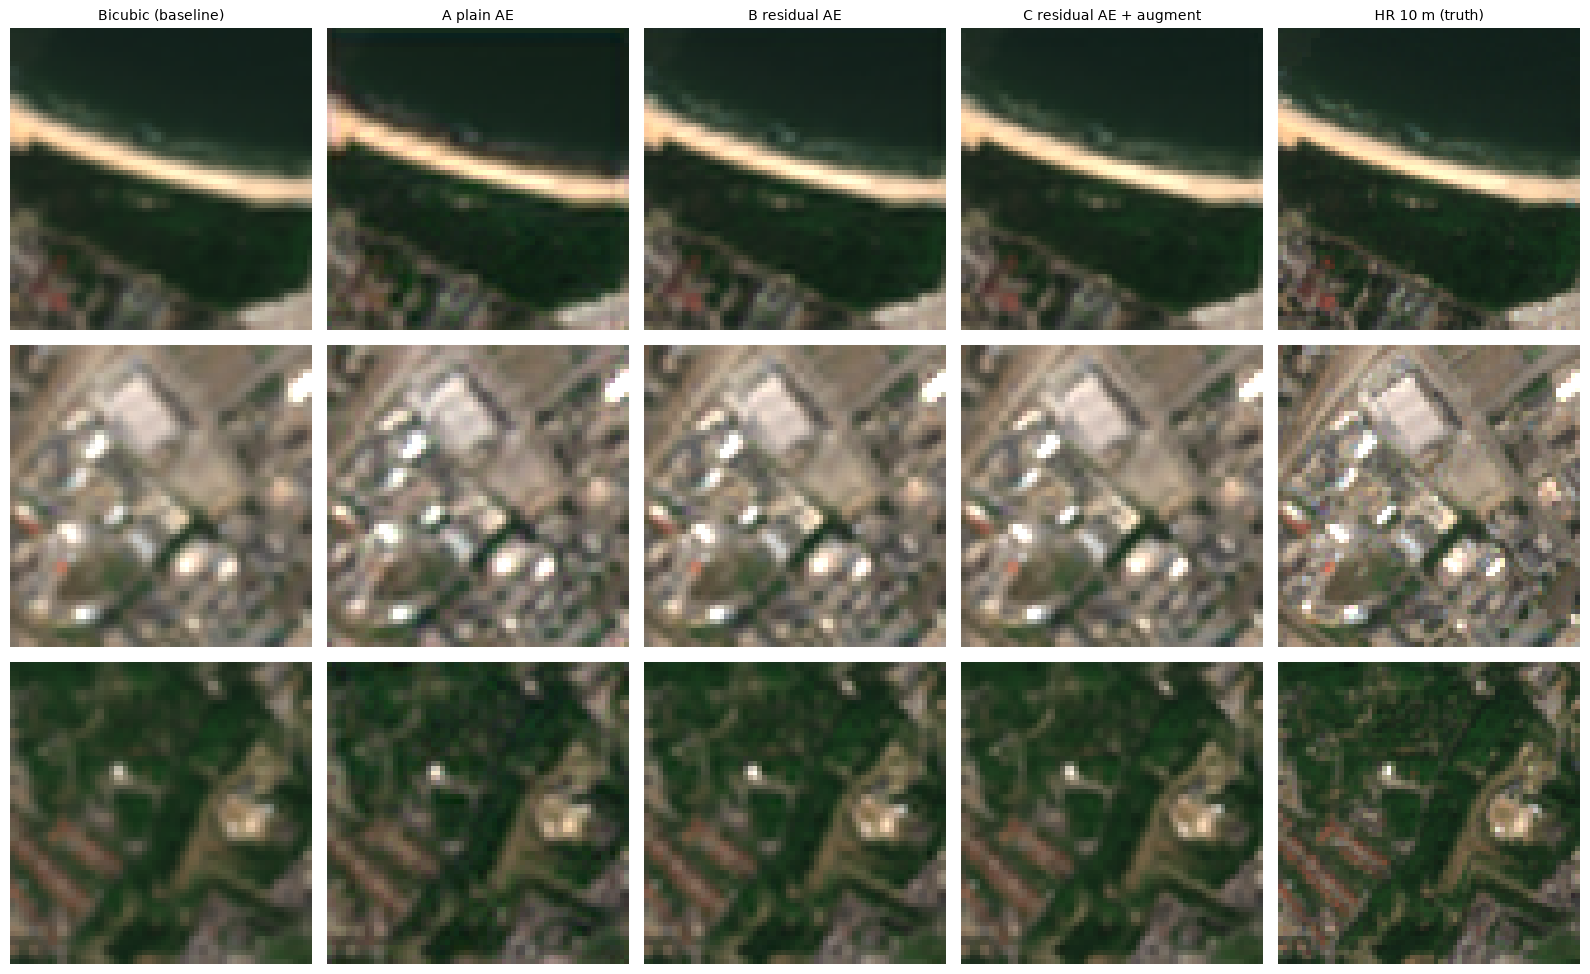

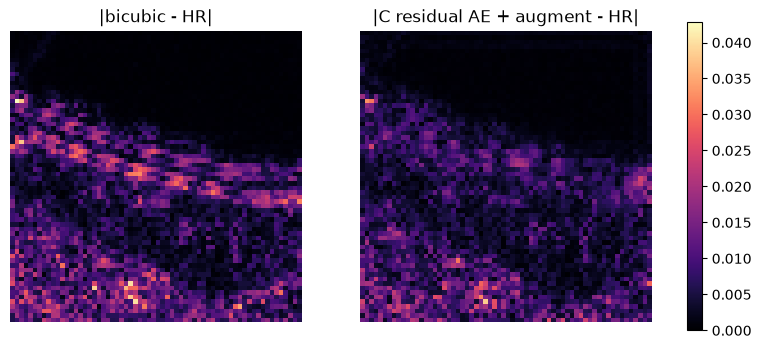

In [28]:
# Visual comparison on test patches
idx = [5, 20, 40]
cols = ['Bicubic (baseline)'] + list(sr_models) + ['HR 10 m (truth)']
fig, axes = plt.subplots(len(idx), len(cols), figsize=(3.2 * len(cols), 3.3 * len(idx)))
for r, i in enumerate(idx):
    for c, name in enumerate(cols):
        img = Y_test[i] if name.startswith('HR') else preds[name][i]
        axes[r, c].imshow(show_rgb(img)); axes[r, c].axis('off')
        if r == 0:
            axes[r, c].set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

# Error maps
best = list(sr_models)[-1]
i = idx[0]
err_bic = np.abs(X_test[i] - Y_test[i]).mean(-1)
err_ae = np.abs(preds[best][i] - Y_test[i]).mean(-1)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
vmax = err_bic.max()
for ax, e, t in zip(axes, [err_bic, err_ae], ['|bicubic - HR|', f'|{best} - HR|']):
    im = ax.imshow(e, cmap='magma', vmin=0, vmax=vmax); ax.set_title(t); ax.axis('off')
plt.colorbar(im, ax=axes, fraction=0.03); plt.show()

### 2.7 Applying the model to the real 10 m image

Finally, the best model is applied to the 10 m image, upsampled ×2 to a 5 m grid.
There is no 5 m ground truth, so this can only be judged visually. The model was trained for 20 m → 10 m and is assumed to work at
the next scale as well.

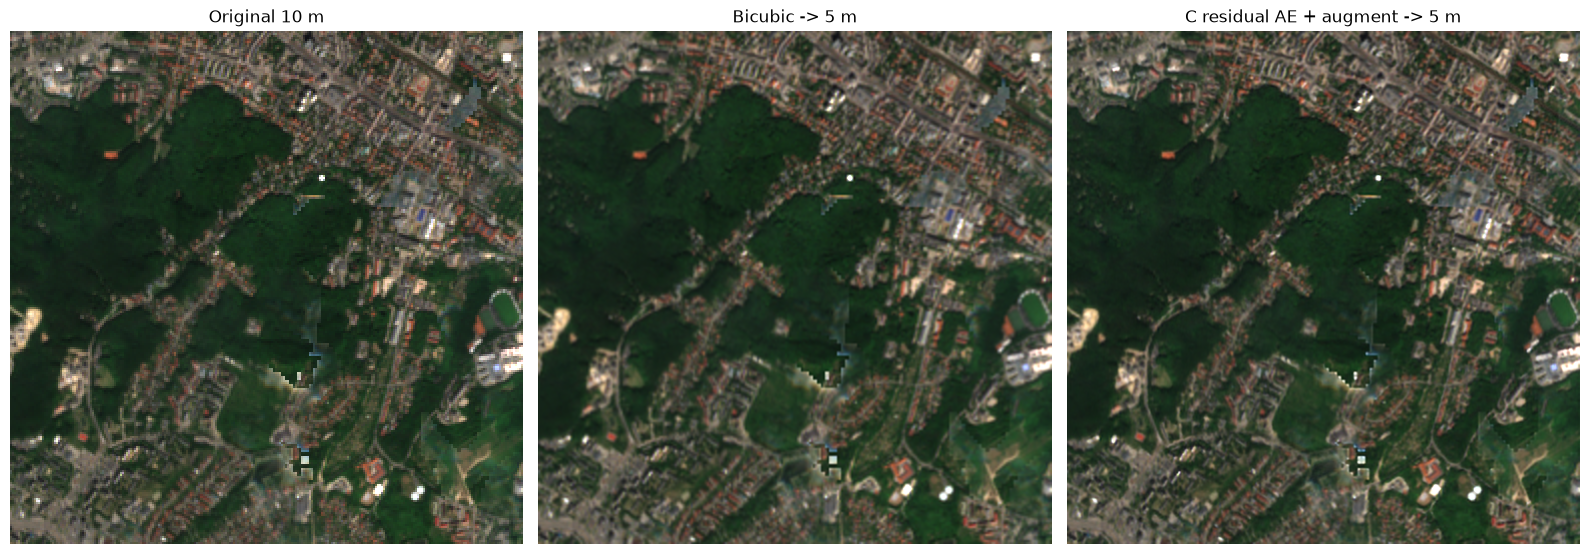

In [29]:
sub = hr[400:656, 400:656]                       # 2.56 km x 2.56 km
sub_up = upsample(sub)                           # bicubic, 5 m grid
sub_sr = sr_models[best].predict(sub_up[None], verbose=False)[0]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
axes[0].imshow(show_rgb(sub), interpolation='nearest'); axes[0].set_title('Original 10 m')
axes[1].imshow(show_rgb(sub_up)); axes[1].set_title('Bicubic -> 5 m')
axes[2].imshow(show_rgb(sub_sr)); axes[2].set_title(f'{best} -> 5 m')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

### 2.8 Findings

**Set-up.** The 10 m Sentinel-2 image of Gdańsk (1024 × 1024 px, B4, B3, B2, B8) was degraded to 20 m (2 × 2 averaging) and upsampled back with bicubic interpolation. 651 training and 64 test patches (64 × 64 px) were cut from spatially separate parts of the image. The auto-encoder has 48 548 parameters.

| Method | PSNR [dB] | SSIM | PSNR gain vs bicubic [dB] |
|---|---|---|---|
| Bicubic (baseline) | 39.11 | 0.942 | 0.00 |
| A plain auto-encoder | 38.39 | 0.946 | −0.72 |
| B residual auto-encoder | 39.85 | 0.955 | +0.74 |
| C residual auto-encoder + augmentation | **40.38** | **0.958** | **+1.27** |

1. **Does it enhance the resolution?** Yes, but only moderately. The best model (C) is 1.27 dB better than bicubic interpolation and has a higher SSIM on test patches it never saw. Visually, the edges are slightly sharper, and the error maps show that the largest bicubic errors — located along edges — are clearly reduced. The fine texture of the built-up areas is still not recovered: all results remain blurrier than the true 10 m image.
2. **Plain vs residual (A vs B).** The plain auto-encoder is *worse* than bicubic (−0.72 dB): it has to rebuild the whole image from the code and after 20 epochs still makes small brightness/colour errors over the whole patch. Its validation loss also starts much higher and decreases slowly. The residual version starts from the bicubic image and only learns the missing high-frequency details (HR − bicubic), which is a much simpler function, so it beats bicubic already after a few epochs (+0.74 dB).
3. **Augmentation (C).** Flips and 90° rotations (8× more training patches) add another +0.53 dB over B, because the network sees edges and structures in all orientations. The lower validation loss of C is not directly comparable with A and B, because its validation split contains rotated copies of training patches; the fair comparison is the independent test area above.
4. **Real 10 m → 5 m.** Applied to the original 10 m image, the model produces a sharper-looking 5 m image than bicubic interpolation, no new details appear — it mainly increases edge contrast. In addition, the model was trained for 20 m → 10 m and is only assumed to work at the next scale, and artefacts of the composite (cloud-mask edges, bright pixels) are sharpened as well.
5. **How can it work better?** More and more varied training data (other cities, seasons) and augmentation; a deeper network with skip connections (e.g. U-Net, EDSR) and longer training; real HR/LR pairs instead of synthetic degradation (e.g. Sentinel-2 with aerial orthophotos), because the real sensor blur is not a 2 × 2 average; and perceptual or GAN losses instead of MSE, which favours blurry results.